# Rabbits and foxes, with `solve_ivp`

**CHME 5137, Lecture 8, Tuesday October 6, 2026.** Started in class, finished for
homework.

*Revised for 2026 by Claude Code (Claude Opus 5.5) from the Lecture 3 notebook, and
checked by Prof. West. The problem is from Chapter 1 of H. Scott Fogler's
"Essentials of Chemical Reaction Engineering". The tasks are new.*

---

There are initially 400 rabbits and 200 foxes on a farm. (Or two cell types in a
96-well plate, if you prefer.) The populations obey

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

* Growth of rabbits, $k_1 = 0.015$ day$^{-1}$
* Death of rabbits being eaten by foxes, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$
* Growth of foxes after eating rabbits, $k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$
* Death of foxes, $k_4 = 0.04$ day$^{-1}$

In Lecture 3 you solved this with Euler's method. You found that the fox peaks,
which should all be the same height, crept upwards. At a step of 0.1 days (12,000
steps for 1200 days) they went 2816, 2854, 2893. At 0.005 days (240,000 steps) they
went 2804.5, 2806.4, 2808.2. Today: how well does a library do, and at what cost?

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Use the in-class notebook**, `solve-ivp-intro.ipynb`, for the syntax.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0

# So here we're defining our variables k1,2,3,4 which are our rate constants for each event 
# Then defining our initial conditions y0 whcih is a list
# Also importing the libraries

## 1. Solve it, and plot it

Write a function `dydt(t, y)` that returns $[dR/dt,\ dF/dt]$. Then call
`solve_ivp` with its **default** settings for 600 days.

Print `sol.success`, `sol.nfev` and `len(sol.t)`. Then plot both populations
against time, with axis labels and a legend.

success: True
function evaluations (nfev): 242
number of time points: 32


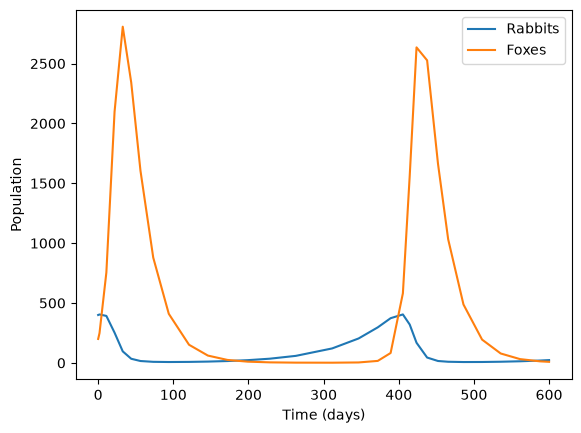

In [2]:
def dydt(t, y):
    R, F = y                      # Our y variable is a list and contains two values rabbits & foxes this assigns a single variable to each one
    dRdt = k1 * R - k2 * R * F    # rabbit equation
    dFdt = k3 * R * F - k4 * F    # fox equation
    return [dRdt, dFdt]

sol = solve_ivp(dydt, (0, 600), y0)   # default settings, from day 0 to day 600 uses RK45 which evaluates the rates at six point

print("success:", sol.success)
print("function evaluations (nfev):", sol.nfev)
print("number of time points:", len(sol.t))

plt.plot(sol.t, sol.y[0], label="Rabbits")
plt.plot(sol.t, sol.y[1], label="Foxes")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.legend()
plt.show()

Your plot is probably jagged. Why? Fix it in two ways: with `t_eval`, and with
`dense_output=True`. Does either one change `sol.nfev`?

default:      nfev = 242   points = 32
t_eval:       nfev = 242   points = 1000
dense_output: nfev = 242   points = 32


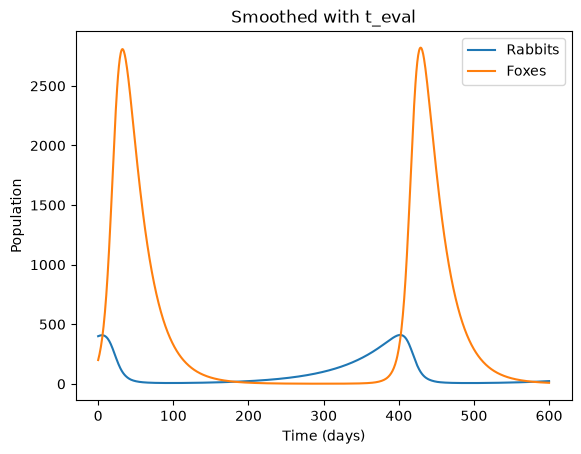

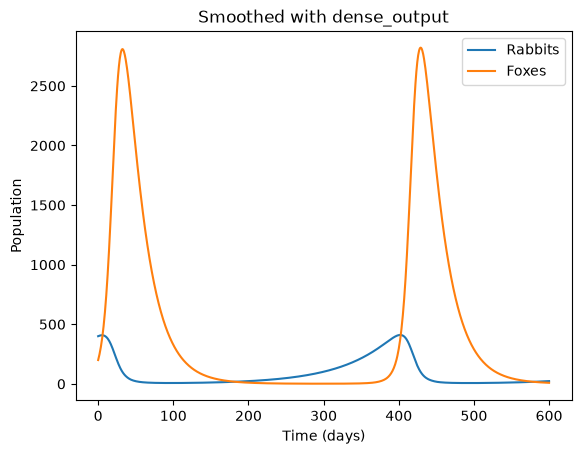

In [3]:
#yes it is jagged

t_plot = np.linspace(0, 600, 1000) # so this should make 1,000 evenly spaced numbers from 0 to 600 which makes for a smoother plot

sol_teval = solve_ivp(dydt, (0, 600), y0, t_eval=t_plot) # t_eval should report the populatio at those 1,000 time points between 0-600 making it save additional time points and smoothing out the graph

sol_dense = solve_ivp(dydt, (0, 600), y0, dense_output=True) #
y_dense = sol_dense.sol(t_plot) #should be the smae as the teval since we set it equal to t_plot which is the same 1,000 points

print("default:      nfev =", sol.nfev, "  points =", len(sol.t))
print("t_eval:       nfev =", sol_teval.nfev, "  points =", len(sol_teval.t))
print("dense_output: nfev =", sol_dense.nfev, "  points =", len(sol_dense.t))

plt.plot(sol_teval.t, sol_teval.y[0], label="Rabbits")
plt.plot(sol_teval.t, sol_teval.y[1], label="Foxes")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.title("Smoothed with t_eval")
plt.legend()
plt.show()

plt.plot(t_plot, y_dense[0], label="Rabbits")
plt.plot(t_plot, y_dense[1], label="Foxes")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.title("Smoothed with dense_output")
plt.legend()
plt.show()



*Answer:* Same nfev for both they take the same rk45 steps the extra points come from polynomoials built out of the already calculated rates

## 2. The phase portrait

Solve to 1200 days, three full cycles, and plot foxes against rabbits. The exact
solution is a closed loop, traced over and over. Is yours?

success: True
nfev: 440


Text(0, 0.5, 'Foxes')

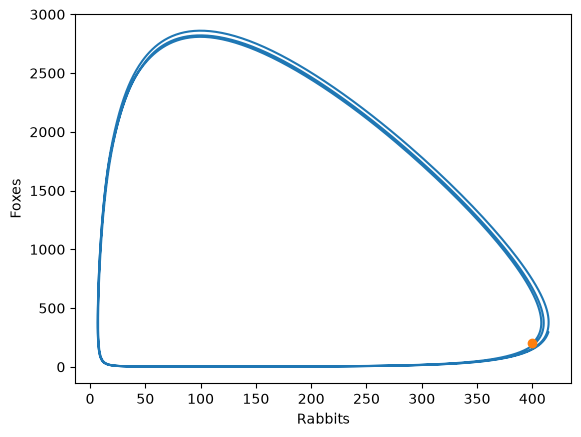

In [4]:
t_long = np.linspace(0, 1200, 5000) #same linespace thing as last time to smooth out the curve but at 5,000 because time is twice as long

sol2 = solve_ivp(dydt, (0, 1200), y0, t_eval = t_long) #same as task 1 but with 1200 days and at 5,000 points

print("success:", sol2.success)
print("nfev:", sol2.nfev)

plt.plot(sol2.y[0], sol2.y[1], label="Solution") #no time plot just the foxes and rabbits against each other

plt.plot(y0[0], y0[1], "o", label="Start") #marks the starting point at initial conditions with an o

plt.xlabel("Rabbits")
plt.ylabel("Foxes")

*Answer:* not closed loop doesn't trace back perfectly the difference is the error

## 3. The height of each fox peak, using events

Searching `sol.y` for the largest value gives you the largest value **at the times
the solver happened to stop**, which won't be exactly at the peak. `solve_ivp` can
find the exact moment instead, with an *event*: a function `g(t, y)` that it
watches. It reports every time `g` passes through zero.

The foxes peak when $dF/dt$ changes from positive to negative. Since
$dF/dt = F(k_3 R - k_4)$ and $F > 0$, that happens when $k_3 R - k_4$ goes from
positive to negative. So:

```python
def fox_peak(t, y):
    R, F = y
    return k3 * R - k4

fox_peak.direction = -1   # only count it when g is decreasing through zero

sol = solve_ivp(dydt, (0, 1200), y0, events=fox_peak)
sol.t_events[0]          # the times of the peaks
sol.y_events[0]          # the [R, F] values at each one
```

Print the time and height of each fox peak, with the default tolerances. Compare
with the Euler peaks above. How many function evaluations did it take, compared
with Euler's 12,000 or 240,000 steps?

In [5]:
def fox_peak(t, y):
    R, F = y
    return k3 * R - k4 # we want to know when the df/dt = 0 to find the peak F is factored out because it's never 0

fox_peak.direction = -1 #makes the function only report the peak not the trough 

sol3 = solve_ivp(dydt, (0, 1200), y0, events=fox_peak) #after each step solve_ivp checks if fox_peak changed sign durin that step, if it did it uses the step's polynomial to find the crossing time

peak_times = sol3.t_events[0] #contains the  crossing times [0] because it crosses the event several times so you just want the first

peak_foxes = sol3.y_events[0][:, 1] #list of fox count at each peak

for t_peak, F_peak in zip(peak_times, peak_foxes):
    print(f"day {t_peak:.1f}: {F_peak:.2f} foxes") #zip pairs the two lists together time with height, the loop runs once per pair

print("nfev:", sol3.nfev)
print("drift (last peak minus first):", peak_foxes[-1] - peak_foxes[0])

day 32.3: 2808.63 foxes
day 429.1: 2821.00 foxes
day 828.5: 2860.88 foxes
nfev: 440
drift (last peak minus first): 52.25290819422298


*Answer:* The euler peaks rise just like the peaks using solveivp but the 0.005 day steps just barely rise while the 0.1 day steps rise more than the RK45. Solveivp called far fewer times 440 compared to both euler step changes (12,000) and (240,000) so much cheaper.

## 4. Required accuracy: `rtol`

The true peaks are all the same height. So the *drift*, last peak minus first, is a
measure of the error, and we don't need the exact answer to find it.

Loop over `rtol` from `1e-3` to `1e-10`, keeping `atol = 1e-8`. For each value
record the drift and `sol.nfev`. Then make two log-log plots: |drift| against
`rtol`, and |drift| against `nfev`. The second is called a *work–precision
diagram*.

- How tight must `rtol` be for the peaks to agree to within one fox? To within
  0.01 of a fox?
- What is the height of the fox peak, to as many significant figures as you can
  justify? How do you know?
- Euler with 240,000 steps had a drift of 3.7 foxes. How many function evaluations
  does `solve_ivp` need to do better than that?

rtol = 0.001   nfev = 440   drift = 52.194331   peaks = [2808.62547286 2820.99373743 2860.81980433]
rtol = 0.0001   nfev = 656   drift = 1.599745   peaks = [2804.0820888  2804.79941736 2805.68183407]
rtol = 1e-05   nfev = 956   drift = 0.081461   peaks = [2803.85591064 2803.89628842 2803.93737205]
rtol = 1e-06   nfev = 1424   drift = 0.010269   peaks = [2803.86674111 2803.87208144 2803.87700974]
rtol = 1e-07   nfev = 2090   drift = -0.000417   peaks = [2803.87041669 2803.86998057 2803.86999976]
rtol = 1e-08   nfev = 3152   drift = -0.000037   peaks = [2803.87012854 2803.87011981 2803.87009113]
rtol = 1e-09   nfev = 4634   drift = 0.000001   peaks = [2803.87009887 2803.87009936 2803.87009971]
rtol = 1e-10   nfev = 6254   drift = -0.000001   peaks = [2803.87009611 2803.87009571 2803.87009534]


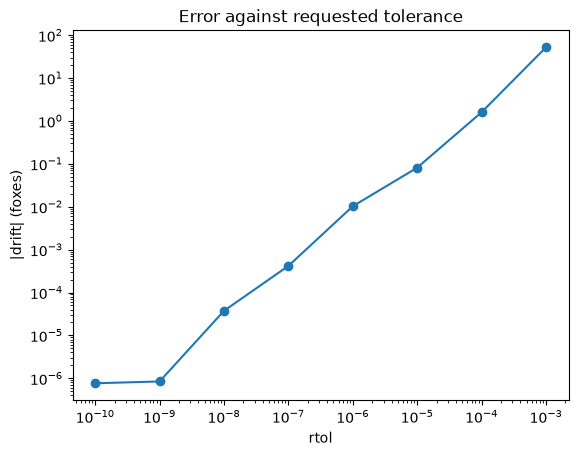

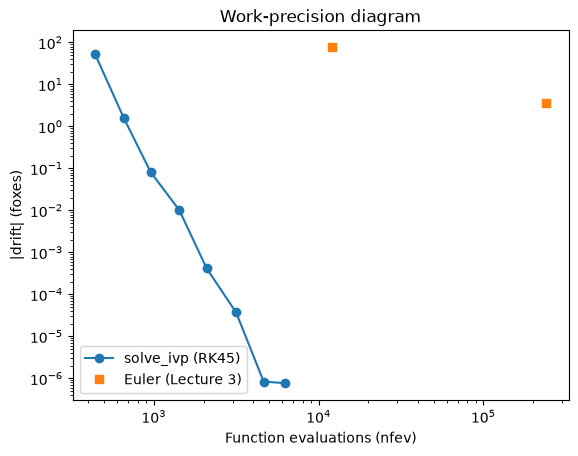

In [6]:
rtols = [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10] #list with the different rtols accuracy settngs

drifts = []
nfevs = []

for rtol in rtols:

    s = solve_ivp(dydt, (0, 1200), y0, events=fox_peak, rtol=rtol, atol=1e-8) #solves same as before with new accuracy setting

    peaks = s.y_events[0][:, 1] #fox count at each peak

    drift = peaks[-1] - peaks[0] #difference between peaks

    drifts.append(drift) #adds the value to the end of the list

    nfevs.append(s.nfev) # same

    print(f"rtol = {rtol}   nfev = {s.nfev}   drift = {drift:.6f}   peaks = {peaks}")

abs_drifts = np.abs(drifts) # stricter settings can have slightly negative drift log plots cant show negative numbers

plt.loglog(rtols, abs_drifts, "o-") #accuracy setting against drift

plt.xlabel("rtol")
plt.ylabel("|drift| (foxes)")
plt.title("Error against requested tolerance")

plt.show()

plt.loglog(nfevs, abs_drifts, "o-", label="solve_ivp (RK45)") #cost against drift

plt.loglog([12000, 240000], [77, 3.7], "s", label="Euler (Lecture 3)") #adds the euler runs from previous lecture

plt.xlabel("Function evaluations (nfev)")
plt.ylabel("|drift| (foxes)")
plt.title("Work-precision diagram")
plt.legend()
plt.show()


*Answer:*
How tight must rtol be for the peaks to agree to within one fox? To within 0.01 of a fox?

10^-5 is the first rtol value to give under 1 fox for the drift

What is the height of the fox peak, to as many significant figures as you can justify? How do you know?

2803.87010 - that's when the values stopped changing for the last two rtol settings

Euler with 240,000 steps had a drift of 3.7 foxes. How many function evaluations does solve_ivp need to do better than that?

first one under 3.7 is rtol 10^-4 which is 1.6 and costs 656 calls. Much less than 240,000

## 5. `atol`, and how few foxes is too few?

What is the **smallest** number of foxes during the cycle, and of rabbits? (Use
`dense_output=True` and a fine grid of times, or another event.)

Now someone argues: "A fraction of a fox is meaningless, so I'll set `atol = 1`."
Try it, with `rtol = 1e-6`. Then try `atol = 10`. What happens to the peaks? Explain
why, using the formula for the error tolerance, $\text{atol} + \text{rtol}\,|y|$.

And about the model itself: what does a population of under two foxes mean? Would a
real population survive that trough? (Lecture 10, kinetic Monte Carlo, is one way
to model that properly.)

In [7]:
sol5 = solve_ivp(dydt, (0, 1200), y0, rtol=1e-10, atol=1e-10, dense_output=True) #solveivp with very strict tolerances

t_fine = np.linspace(0, 1200, 120001) #ever finer than anything we've plotted before so we can find the true bottom

y_fine = sol5.sol(t_fine) # population at all those times from t_fine, over 120,000

print("smallest rabbits:", y_fine[0].min(), "on day", t_fine[y_fine[0].argmin()]) #position of smallest value in the list then t fine uses position to find matchig time
print("smallest foxes:  ", y_fine[1].min(), "on day", t_fine[y_fine[1].argmin()])

for atol in [1e-8, 1, 10]: #loops atol values

    s = solve_ivp(dydt, (0, 1200), y0, events=fox_peak, rtol=1e-6, atol=atol) #same as task four but now rtol is constant and atol changes

    peaks = s.y_events[0][:, 1] #same as task 4

    print(f"atol = {atol}   nfev = {s.nfev}   number of peaks = {len(peaks)}   peaks = {peaks}")


smallest rabbits: 7.42607175390857 on day 491.89
smallest foxes:   1.593636791879883 on day 692.99
atol = 1e-08   nfev = 1424   number of peaks = 3   peaks = [2803.86674111 2803.87208144 2803.87700974]
atol = 1   nfev = 368   number of peaks = 4   peaks = [2804.04832059 2675.90606983 2649.84546395 2531.29436986]
atol = 10   nfev = 344   number of peaks = 4   peaks = [2804.20992471 2593.16364437 2544.83632657 2315.84125382]


*Answer:* 1.594 rabbits and 7.426 foxes

When atol is 1 and 10 there's a 4th peak and the peaks drop off each cycle. At peak the allowance is 1 fox out of 2804 at the bottom it's 1 out of 1.59 which is 63% or 10 / 1.59 so the bottom solver is allowed to get them completely wrong because the tolerances are so large

no under two foxes wouldn't survive, near bottom is not accurate


## 6. Which method?

At `rtol = 1e-8, atol = 1e-8`, compare `method=` `"RK45"`, `"DOP853"`, `"LSODA"`,
`"BDF"` and `"Radau"`: drift and `nfev` for each. Which is cheapest for this
problem? Is this problem stiff? How can you tell?

*Answer:*

## Stretch problems

**(a)** For this system the quantity
$V = k_3 R - k_4 \ln R + k_2 F - k_1 \ln F$ stays exactly constant. (Differentiate
it and substitute the two ODEs to check.) That's why the orbit is closed. Plot
how much $V$ changes over 1200 days for a few values of `rtol`. Is it a better
measure of the error than the peak drift?

**(b)** Re-run with $k_3 = 0.00004$ day$^{-1}$ rabbits$^{-1}$ for 800 days, as in
Lecture 3. The fixed point moves from (100, 375) to (1000, 375). Do your
conclusions about `rtol` change?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.